
# UrbanPulse AI — Deep Learning Forecasting

## LSTM-Based One-Hour-Ahead PM2.5 Prediction

**Project:** UrbanPulse AI  
**Dataset:** UCI Beijing Multi-Site Air Quality  
**Station:** Aotizhongxin  
**Forecast Horizon:** One hour ahead  
**Experiment Stage:** Milestone 4 — Deep Learning Forecasting

---

## 1. Research Objective

This experiment investigates whether a Long Short-Term Memory (LSTM)
neural network can learn temporal patterns in air pollution data and
predict PM2.5 concentration one hour into the future.

The experiment builds on the machine-learning baselines developed in
`03_real_data_exploration.ipynb`.

The objective is not to assume that deep learning will outperform
traditional machine learning, but to evaluate its performance using
a consistent forecasting setup.

### Research Questions

1. Can an LSTM learn useful temporal patterns from sequential pollution
   and environmental observations?
2. How does its validation performance compare with a persistence
   baseline?
3. What limitations remain when forecasting sudden or extreme pollution
   events?

### Scope of This Experiment

This notebook focuses on a single monitoring station and a one-hour
forecast horizon. Spatial modelling, satellite data integration,
anomaly detection, and scenario simulation will be addressed in later
project stages.

### Experimental Principles

- Preserve chronological ordering.
- Avoid future information and data leakage.
- Fit preprocessing transformations using training data only.
- Evaluate against a simple persistence baseline.
- Record limitations and results honestly.


In [1]:

import sys
import importlib.util

print("Python executable:", sys.executable)
print("Python version:", sys.version)

for package in ["tensorflow", "torch", "keras"]:
    print(f"{package} installed:", importlib.util.find_spec(package) is not None)


Python executable: C:\UrbanPulse-AI\.venv\Scripts\python.exe
Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
tensorflow installed: True
torch installed: False
keras installed: True


In [2]:

# 2.1 — Verify Python environment and required libraries

import sys
import importlib.util

print("Python executable:", sys.executable)
print("Python version:", sys.version)

required_packages = ["numpy", "pandas", "sklearn"]
optional_deep_learning_packages = ["tensorflow", "torch"]

print("\nRequired packages:")
for package in required_packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Available' if installed else 'Missing'}")

print("\nDeep-learning frameworks:")
for package in optional_deep_learning_packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Available' if installed else 'Not installed'}")


Python executable: C:\UrbanPulse-AI\.venv\Scripts\python.exe
Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]

Required packages:
numpy: Available
pandas: Available
sklearn: Available

Deep-learning frameworks:
tensorflow: Available
torch: Not installed



## 2.2 — Verify the Deep-Learning Framework

TensorFlow is used to implement the LSTM forecasting model.
This section verifies that TensorFlow imports correctly and reports
the available computing devices before model development begins.


In [3]:

# 2.2 — Verify TensorFlow installation

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

# Reproducibility seeds for this experiment
tf.keras.utils.set_random_seed(42)

print("\nRandom seed set to 42.")


TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

Random seed set to 42.


# 2.3 — Load the Raw Air Quality Dataset

In this section, we load the original Aotizhongxin monitoring-station dataset into memory.

**Objective:** Establish a reproducible starting point for data inspection and quality assessment.

**Important:** The raw dataset will remain unchanged. All cleaning and feature engineering will be performed on separate working copies.

In [4]:

from pathlib import Path
import pandas as pd
import numpy as np

# Define project and dataset paths
PROJECT_DIR = Path(r"C:\UrbanPulse-AI")

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "raw"
    / "beijing"
    / "extracted"
    / "PRSA_Data_20130301-20170228"
    / "PRSA_Data_Aotizhongxin_20130301-20170228.csv"
)

# Confirm that the dataset exists before loading it
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}"
    )

# Load the original station dataset
station_df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Shape:", station_df.shape)
print("\nFirst five rows:")
display(station_df.head())

print("\nDataset columns:")
print(station_df.columns.tolist())


Dataset loaded successfully.
Shape: (35064, 18)

First five rows:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin



Dataset columns:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']


## 2.4 — Missing-Data Assessment

Before preprocessing, we quantify missing observations in every feature.

This step helps us:
- Compare the amount of missing data across pollutants and meteorological variables.
- Identify variables that require closer investigation.
- Decide how to handle missing values without distorting genuine pollution peaks.
- Establish a documented baseline before cleaning or imputation.

**Important:** We will preserve the raw dataset and perform subsequent preprocessing on a separate working copy. Missing values will not be filled until their patterns and consecutive gap lengths have been examined.

### 2.4 — Verify the Raw Dataset

Before preprocessing, verify the dataset dimensions, column types, missing observations, and duplicate records.

These checks establish the baseline data quality before any transformations are applied.

In [5]:

# 2.4.1 — Calculate missing-value counts and percentages

import pandas as pd
import numpy as np

# Work with a separate copy; do not modify the raw dataframe.
missing_audit = station_df.isna().sum().to_frame("Missing_Count")

missing_audit["Missing_Percentage"] = (
    missing_audit["Missing_Count"] / len(station_df) * 100
).round(3)

missing_audit["Available_Count"] = (
    len(station_df) - missing_audit["Missing_Count"]
)

missing_audit = missing_audit.sort_values(
    "Missing_Percentage",
    ascending=False
)

print("Dataset shape:", station_df.shape)
print("Total missing values:", int(station_df.isna().sum().sum()))
print("\nMissing-value assessment:")
display(missing_audit)


Dataset shape: (35064, 18)
Total missing values: 7271

Missing-value assessment:


,Missing_Count,Missing_Percentage,Available_Count
CO,1776,5.065,33288
O3,1719,4.902,33345
NO2,1023,2.918,34041
SO2,935,2.667,34129
PM2.5,925,2.638,34139
PM10,718,2.048,34346
wd,81,0.231,34983
RAIN,20,0.057,35044
DEWP,20,0.057,35044
PRES,20,0.057,35044


In [6]:

# Inspect dataset structure
print("Dataset dimensions:", station_df.shape)

print("\nColumn data types:")
display(station_df.dtypes.to_frame("Data Type"))

print("\nMissing values by column:")
missing_audit = pd.DataFrame({
    "Missing_Count": station_df.isna().sum(),
    "Missing_Percentage": (
        station_df.isna().mean() * 100
    ).round(2)
})
display(missing_audit.sort_values(
    "Missing_Count", ascending=False
))

print("\nDuplicate rows:", station_df.duplicated().sum())


Dataset dimensions: (35064, 18)

Column data types:


,Data Type
No,int64
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64



Missing values by column:


,Missing_Count,Missing_Percentage
CO,1776,5.07
O3,1719,4.90
NO2,1023,2.92
SO2,935,2.67
PM2.5,925,2.64
PM10,718,2.05
wd,81,0.23
RAIN,20,0.06
DEWP,20,0.06
PRES,20,0.06



Duplicate rows: 0



## 3. Dataset Loading and Inspection

### Objective

Load the prepared Aotizhongxin station dataset and verify its structure
before constructing sequential inputs for the LSTM.

We will inspect the available variables, timestamp coverage, missing
values, and target-related columns. This step ensures that the model
uses the intended forecasting target and that the data remains in
chronological order.

### Data Integrity Rules

- Preserve the chronological order of observations.
- Identify the existing target column instead of recreating it blindly.
- Distinguish predictors from targets and metadata.
- Check for missing values before sequence construction.
- Do not assume that every column in the dataset is safe to use.


In [7]:

# 3.1 — Locate available project datasets

from pathlib import Path

PROJECT_ROOT = Path(r"C:\UrbanPulse-AI")

print("Project root exists:", PROJECT_ROOT.exists())

print("\nPotential prepared datasets:")
for folder_name in ["data/processed", "data/interim", "data/raw"]:
    folder = PROJECT_ROOT / folder_name
    print(f"\n{folder_name}:")

    if folder.exists():
        files = [
            path for path in folder.rglob("*")
            if path.is_file()
            and path.suffix.lower() in {".csv", ".parquet", ".feather"}
        ]

        if files:
            for path in files[:30]:
                print(" -", path.relative_to(PROJECT_ROOT))
            if len(files) > 30:
                print(f" ... and {len(files) - 30} more files")
        else:
            print(" No CSV, Parquet, or Feather files found.")
    else:
        print(" Folder does not exist.")


Project root exists: True

Potential prepared datasets:

data/processed:
 No CSV, Parquet, or Feather files found.

data/interim:
 No CSV, Parquet, or Feather files found.

data/raw:
 - data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Aotizhongxin_20130301-20170228.csv
 - data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Changping_20130301-20170228.csv
 - data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Dingling_20130301-20170228.csv
 - data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Dongsi_20130301-20170228.csv
 - data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Guanyuan_20130301-20170228.csv
 - data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Gucheng_20130301-20170228.csv
 - data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Huairou_20130301-20170228.csv
 - data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Nongzhanguan_20130301-20170228.csv
 - data\raw\beijing\


### 3.2 — Load the Aotizhongxin Station Dataset

The source dataset contains hourly air-quality and meteorological
observations from Beijing. This experiment uses the Aotizhongxin
monitoring station.

The raw data will be loaded into a new DataFrame. Initial inspection
will verify the column names, dimensions, data types, timestamp fields,
and missing values before any transformations are applied.

The original CSV remains unchanged.


In [8]:

# 3.2 — Load and inspect raw station data

import pandas as pd
from pathlib import Path

DATA_PATH = (
    Path(r"C:\UrbanPulse-AI")
    / "data"
    / "raw"
    / "beijing"
    / "extracted"
    / "PRSA_Data_20130301-20170228"
    / "PRSA_Data_Aotizhongxin_20130301-20170228.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

raw_df = pd.read_csv(DATA_PATH)

print("Dataset shape:", raw_df.shape)
print("\nColumn names:")
print(raw_df.columns.tolist())

print("\nFirst five rows:")
display(raw_df.head())

print("\nData types:")
display(raw_df.dtypes.to_frame("Data type"))

print("\nMissing values by column:")
display(
    raw_df.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing values")
)


Dataset shape: (35064, 18)

Column names:
['No', 'year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station']

First five rows:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin



Data types:


,Data type
No,int64
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64



Missing values by column:


,Missing values
CO,1776
O3,1719
NO2,1023
SO2,935
PM2.5,925
PM10,718
wd,81
RAIN,20
DEWP,20
PRES,20


# UrbanPulse AI — Deep-Learning Forecasting

## 4.1 — Project Overview and Research Objective

### Project Background

UrbanPulse AI is an AI-powered urban air-pollution forecasting project that investigates how historical pollutant concentrations, meteorological conditions, and temporal patterns can support more reliable air-quality predictions.

The project progresses from exploratory data analysis and conventional machine-learning models toward deep-learning-based temporal forecasting.

### Research Objective

The objective of this experiment is to investigate whether deep-learning models can learn temporal dependencies in air-quality observations and improve one-hour-ahead PM2.5 forecasting.

### Dataset

- **Source:** UCI Beijing Multi-Site Air Quality dataset
- **Monitoring station:** Aotizhongxin, Beijing
- **Observation frequency:** Hourly
- **Raw observations:** 35,064
- **Forecast target:** PM2.5 concentration one hour into the future
- **Experimental framework:** TensorFlow/Keras

### Planned Experimental Approach

1. Validate the Python environment and dataset.
2. Construct chronological training, validation, and test partitions.
3. Prepare time-ordered input sequences without future-data leakage.
4. Establish a persistence baseline and, where appropriate, compare against previous machine-learning results.
5. Train an initial LSTM forecasting model.
6. Evaluate MAE, RMSE, and R² on comparable observations.
7. Investigate performance during high-pollution episodes.
8. Record limitations and determine the next experiment from observed results.

### Reproducibility and Data Integrity

The raw dataset and previous analysis notebooks will remain unchanged. Preprocessing parameters will be fitted using training data only, and validation data will guide model selection.

The test period will be reserved for final evaluation as far as the previous exploratory experiments permit. Because the earlier test period has already been examined, results from a new model evaluated on that same period must be interpreted as exploratory rather than as a completely untouched final estimate.

No deep-learning model is assumed to outperform the existing baselines before evaluation.

In [9]:
# 4.2 — Verify the deep-learning environment

import sys
import importlib.util
import platform

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Operating system:", platform.platform())

required_packages = [
    "numpy",
    "pandas",
    "sklearn",
    "tensorflow",
]

print("\nRequired packages:")
for package in required_packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Available' if installed else 'MISSING'}")

if importlib.util.find_spec("tensorflow") is None:
    raise ImportError(
        "TensorFlow is unavailable in the active Python environment."
    )

import tensorflow as tf

print("\nTensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

tf.keras.utils.set_random_seed(42)

print("\nReproducibility seed set to 42.")

Python executable: C:\UrbanPulse-AI\.venv\Scripts\python.exe
Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Operating system: Windows-11-10.0.26100-SP0

Required packages:
numpy: Available
pandas: Available
sklearn: Available
tensorflow: Available

TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

Reproducibility seed set to 42.


In [10]:

from pathlib import Path

# UrbanPulse AI — Inspect existing data and experiment artifacts
# This is a read-only inventory. No files are created or modified.

PROJECT_DIR = Path(r"C:\UrbanPulse-AI")

for folder_name in ["data", "experiments", "reports", "models"]:
    folder = PROJECT_DIR / folder_name

    print(f"\n{'=' * 60}")
    print(f"{folder_name}/")

    if not folder.exists():
        print("Folder does not exist.")
        continue

    files = [
        path for path in folder.rglob("*")
        if path.is_file()
    ]

    if not files:
        print("No files found.")
        continue

    for path in sorted(files):
        print(path.relative_to(PROJECT_DIR))



data/
data\raw\beijing\beijing_air_quality.zip
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Aotizhongxin_20130301-20170228.csv
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Changping_20130301-20170228.csv
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Dingling_20130301-20170228.csv
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Dongsi_20130301-20170228.csv
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Guanyuan_20130301-20170228.csv
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Gucheng_20130301-20170228.csv
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Huairou_20130301-20170228.csv
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Nongzhanguan_20130301-20170228.csv
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Shunyi_20130301-20170228.csv
data\raw\beijing\extracted\PRSA_Data_20130301-20170228\PRSA_Data_Tiantan_20130301-201

## 4.3 — Construct and Validate the Hourly Timeline

### Objective

Convert the separate year, month, day, and hour columns into a proper datetime index. Verify that observations are ordered chronologically and determine whether the dataset contains duplicate timestamps or gaps in its hourly timeline.

### Why This Matters

An LSTM learns from sequences, so the temporal order of observations must be correct. Missing hours or duplicated timestamps can cause input windows to represent misleading time intervals.

### Data Integrity Rules

- Preserve the original raw dataset.
- Perform transformations on a separate working copy.
- Retain the original hourly observations without resampling.
- Verify timestamp uniqueness and hourly continuity before creating sequences.
- Do not impute missing pollutant measurements or create forecasting targets in this step.

In [11]:

# 4.3.1 — Create and validate the datetime index

import pandas as pd

# Confirm that the expected DataFrame is available.
if "raw_df" not in globals():
    raise NameError(
        "raw_df is unavailable. Run Section 3.2 first."
    )

# Create a working copy; preserve the original DataFrame.
timeline_df = raw_df.copy()

# Construct timestamps from the original calendar columns.
timeline_df["timestamp"] = pd.to_datetime(
    timeline_df[["year", "month", "day", "hour"]]
)

# Sort chronologically and use timestamps as the index.
timeline_df = (
    timeline_df
    .sort_values("timestamp")
    .set_index("timestamp")
)

# Validate chronological ordering.
is_chronological = timeline_df.index.is_monotonic_increasing

# Check for duplicated hourly timestamps.
duplicate_timestamps = int(
    timeline_df.index.duplicated().sum()
)

# Check whether consecutive observations are exactly one hour apart.
hourly_differences = timeline_df.index.to_series().diff()
non_hourly_intervals = int(
    (hourly_differences.iloc[1:] != pd.Timedelta(hours=1)).sum()
)

# Report the timeline validation results.
print("Timeline validation")
print("-" * 40)
print("Observations:", len(timeline_df))
print("Chronologically ordered:", is_chronological)
print("First timestamp:", timeline_df.index.min())
print("Last timestamp:", timeline_df.index.max())
print("Duplicate timestamps:", duplicate_timestamps)
print("Non-hourly intervals:", non_hourly_intervals)

print("\nFirst five timestamped observations:")
display(timeline_df.head())

# Stop if timestamp integrity checks fail.
if not is_chronological:
    raise ValueError("The timeline is not chronologically ordered.")

if duplicate_timestamps > 0:
    raise ValueError("Duplicate timestamps require investigation.")


Timeline validation
----------------------------------------
Observations: 35064
Chronologically ordered: True
First timestamp: 2013-03-01 00:00:00
Last timestamp: 2017-02-28 23:00:00
Duplicate timestamps: 0
Non-hourly intervals: 0

First five timestamped observations:


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
timestamp,,,,,,,,,,,,,,,,,,
2013-03-01 00:00:00,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
2013-03-01 01:00:00,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2013-03-01 02:00:00,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
2013-03-01 03:00:00,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
2013-03-01 04:00:00,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


### 4.4 — Prepare the LSTM Forecasting Dataset

This section defines the input features and forecasting target for the LSTM experiment. The model will use the previous 24 hours of observations to predict PM2.5 concentration one hour into the future.

The observations will remain in chronological order. Missing target values will not be fabricated, and preprocessing parameters will be learned from the training period only to prevent data leakage.

In [12]:

# 4.4 — Prepare the one-hour-ahead forecasting dataset

import numpy as np
import pandas as pd

# Use the already-loaded raw dataset.
if "raw_df" not in globals():
    raise NameError("raw_df is unavailable. Run the existing data-loading cell.")

source_df = raw_df.copy()

# Reconstruct timestamps and preserve hourly chronological order.
source_df["timestamp"] = pd.to_datetime(
    source_df[["year", "month", "day", "hour"]]
)
source_df = source_df.sort_values("timestamp").reset_index(drop=True)

# Numeric observations available at the current forecasting hour.
feature_columns = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

missing_columns = [
    col for col in feature_columns if col not in source_df.columns
]
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

# Keep only the timestamp and selected numeric predictors.
lstm_df = source_df[["timestamp"] + feature_columns].copy()

# Each input row at time t predicts the measured PM2.5 at time t+1.
lstm_df["target_PM2.5_next_hour"] = lstm_df["PM2.5"].shift(-1)
lstm_df["target_timestamp"] = lstm_df["timestamp"].shift(-1)

# The final input row has no next-hour target.
lstm_df = lstm_df.iloc[:-1].copy().reset_index(drop=True)

# Preserve the chronological boundaries from the earlier experiment.
TRAIN_END = pd.Timestamp("2015-12-18 15:00:00")
VAL_START = pd.Timestamp("2015-12-18 16:00:00")
VAL_END = pd.Timestamp("2016-07-24 19:00:00")
TEST_START = pd.Timestamp("2016-07-24 20:00:00")

target_time = lstm_df["target_timestamp"]

# Split according to the time being predicted, not the input-row time.
train_mask = target_time <= TRAIN_END
val_mask = target_time.between(VAL_START, VAL_END)
test_mask = target_time >= TEST_START

train_df = lstm_df.loc[train_mask].copy()
val_df = lstm_df.loc[val_mask].copy()
test_df = lstm_df.loc[test_mask].copy()

print("Forecasting dataset prepared")
print("-" * 50)
print("Supervised rows:", len(lstm_df))
print("Input features:", len(feature_columns))
print("Lookback planned: 24 hours")
print("Forecast horizon: 1 hour")

for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(f"\n{name}: {len(part):,} rows")
    print("Input time:", part["timestamp"].min(), "to", part["timestamp"].max())
    print(
        "Target time:",
        part["target_timestamp"].min(),
        "to",
        part["target_timestamp"].max(),
    )
    print(
        "Missing next-hour targets:",
        int(part["target_PM2.5_next_hour"].isna().sum()),
    )

print("\nAll target timestamps assigned to exactly one partition:",
      int(train_mask.sum() + val_mask.sum() + test_mask.sum()) == len(lstm_df))


Forecasting dataset prepared
--------------------------------------------------
Supervised rows: 35063
Input features: 11
Lookback planned: 24 hours
Forecast horizon: 1 hour

Training: 24,543 rows
Input time: 2013-03-01 00:00:00 to 2015-12-18 14:00:00
Target time: 2013-03-01 01:00:00 to 2015-12-18 15:00:00
Missing next-hour targets: 730

Validation: 5,260 rows
Input time: 2015-12-18 15:00:00 to 2016-07-24 18:00:00
Target time: 2015-12-18 16:00:00 to 2016-07-24 19:00:00
Missing next-hour targets: 108

Test: 5,260 rows
Input time: 2016-07-24 19:00:00 to 2017-02-28 22:00:00
Target time: 2016-07-24 20:00:00 to 2017-02-28 23:00:00
Missing next-hour targets: 87

All target timestamps assigned to exactly one partition: True


4.5 — Investigate missing values in the training data
Before deciding how to treat missing values, we need to identify which of the 11 input features contain them, how many consecutive missing hours occur, and whether missing PM2.5 targets can be excluded from supervised training.

In [13]:

# 4.5 — Diagnose missing predictors and forecasting targets

print("Missing values in the training partition")
print("-" * 50)

missing_audit = pd.DataFrame({
    "Missing_Count": train_df[feature_columns].isna().sum(),
    "Missing_Percentage": (
        train_df[feature_columns].isna().mean() * 100
    ).round(3),
})

display(missing_audit.sort_values("Missing_Count", ascending=False))

target_col = "target_PM2.5_next_hour"

print("\nTarget-quality assessment")
print("-" * 50)
print("Training targets:", len(train_df))
print("Missing training targets:", int(train_df[target_col].isna().sum()))
print("Available training targets:", int(train_df[target_col].notna().sum()))
print("Missing validation targets:", int(val_df[target_col].isna().sum()))
print("Missing test targets:", int(test_df[target_col].isna().sum()))

# Missing-target runs are measured in chronological training order.
missing_target = train_df[target_col].isna().reset_index(drop=True)

run_ids = missing_target.ne(
    missing_target.shift(fill_value=False)
).cumsum()

missing_runs = missing_target[missing_target].groupby(
    run_ids[missing_target]
).size()

print("\nConsecutive missing next-hour target runs")
if missing_runs.empty:
    print("No missing target runs.")
else:
    print("Number of runs:", len(missing_runs))
    print("Longest run (hours):", int(missing_runs.max()))
    print("Runs of 1 hour:", int((missing_runs == 1).sum()))
    print("Runs of 2–6 hours:", int(missing_runs.between(2, 6).sum()))
    print("Runs longer than 6 hours:", int((missing_runs > 6).sum()))


Missing values in the training partition
--------------------------------------------------


,Missing_Count,Missing_Percentage
CO,1592,6.487
O3,1407,5.733
SO2,777,3.166
NO2,777,3.166
PM2.5,730,2.974
PM10,590,2.404
TEMP,2,0.008
PRES,2,0.008
DEWP,2,0.008
RAIN,2,0.008



Target-quality assessment
--------------------------------------------------
Training targets: 24543
Missing training targets: 730
Available training targets: 23813
Missing validation targets: 108
Missing test targets: 87

Consecutive missing next-hour target runs
Number of runs: 130
Longest run (hours): 343
Runs of 1 hour: 66
Runs of 2–6 hours: 55
Runs longer than 6 hours: 9



## 4.6 — Preprocessing and Feature Scaling

### Objective

Prepare numerical input features for LSTM training while preserving
the chronological structure of the observations.

### Missing-Data Strategy

- Fit a median imputer on the training input period only.
- Apply the fitted imputer to training, validation, and test features.
- Do not impute missing forecasting targets.
- Fit the feature scaler on imputed training features only.
- Fit the target scaler using observed training targets only.

### Leakage Prevention

Validation and test observations must not influence the fitted
imputation values or scaling parameters. Historical observations
from earlier periods may still be used as sequence context when
forecasting later periods, because those observations would already
be available at prediction time.


In [14]:

# 4.6 — Fit preprocessing transformations on training data only

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# The training samples predict target times through TRAIN_END.
# Their latest input observation is one hour earlier.
training_input_mask = lstm_df["timestamp"] <= (
    TRAIN_END - pd.Timedelta(hours=1)
)

training_input_features = lstm_df.loc[
    training_input_mask, feature_columns
]

if training_input_features.empty:
    raise ValueError("No training input observations are available.")

# Fit the feature imputer on training observations only.
feature_imputer = SimpleImputer(strategy="median")
feature_imputer.fit(training_input_features)

# Transform every input row using the same fitted imputer.
X_imputed = feature_imputer.transform(lstm_df[feature_columns])

# Fit the feature scaler on training observations only.
feature_scaler = StandardScaler()
feature_scaler.fit(
    feature_imputer.transform(training_input_features)
)

X_scaled = feature_scaler.transform(X_imputed).astype(np.float32)

# Fit a separate target scaler on observed training targets only.
observed_training_targets = train_df[target_col].dropna().to_numpy(
    dtype=np.float64
)

if len(observed_training_targets) == 0:
    raise ValueError("No observed training targets are available.")

target_scaler = StandardScaler()
target_scaler.fit(observed_training_targets.reshape(-1, 1))

print("Preprocessing complete")
print("-" * 50)
print("Scaled input shape:", X_scaled.shape)
print("Input feature count:", X_scaled.shape[1])
print("Feature imputer fitted on training rows:", len(training_input_features))
print("Observed training targets used for target scaling:",
      len(observed_training_targets))
print("Missing values after input imputation:",
      int(np.isnan(X_scaled).sum()))
print("All scaled features finite:", bool(np.isfinite(X_scaled).all()))
print("All target-scaler parameters finite:",
      bool(np.isfinite(target_scaler.mean_).all()))


Preprocessing complete
--------------------------------------------------
Scaled input shape: (35063, 11)
Input feature count: 11
Feature imputer fitted on training rows: 24543
Observed training targets used for target scaling: 23813
Missing values after input imputation: 0
All scaled features finite: True
All target-scaler parameters finite: True



## 4.7 — Construct Sequential Input Windows

### Objective

Construct overlapping sequences containing the previous 24 hourly
observations. Each sequence predicts PM2.5 one hour after its final
input observation.

### Sequence Design

- **Input length:** 24 consecutive hours.
- **Forecast horizon:** 1 hour ahead.
- **Input features:** 11 numerical pollutant and meteorological variables.
- **Target:** measured PM2.5 at the next hour.

### Boundary Handling

Training sequences use training-period history. Validation sequences
may use earlier training observations as historical context, and test
sequences may use earlier training and validation observations.

No sequence is allowed to use observations later than its prediction
time. Samples with missing target values are excluded; input gaps are
handled using the training-fitted imputer.


In [15]:

# 4.7 — Build chronological 24-hour sequences

LOOKBACK = 24

target_values = lstm_df[target_col].to_numpy(dtype=np.float32)
target_timestamps = lstm_df["target_timestamp"]
input_pm25 = lstm_df["PM2.5"].to_numpy(dtype=np.float32)

def build_sequences(split_mask, split_name):
    X_sequences = []
    y_values = []
    current_pm25_values = []
    prediction_times = []

    split_mask = np.asarray(split_mask, dtype=bool)

    for i in range(LOOKBACK - 1, len(lstm_df)):
        # The sequence ends at the current input hour.
        # The label belongs to the following hour.
        if not split_mask[i]:
            continue

        # Missing targets must never become training labels.
        if not np.isfinite(target_values[i]):
            continue

        X_sequences.append(
            X_scaled[i - LOOKBACK + 1 : i + 1]
        )
        y_values.append(target_values[i])
        current_pm25_values.append(input_pm25[i])
        prediction_times.append(target_timestamps.iloc[i])

    if not X_sequences:
        raise ValueError(f"No valid sequences created for {split_name}.")

    X_out = np.asarray(X_sequences, dtype=np.float32)
    y_out = np.asarray(y_values, dtype=np.float32)
    current_out = np.asarray(current_pm25_values, dtype=np.float32)
    times_out = pd.to_datetime(prediction_times)

    print(
        f"{split_name}: X={X_out.shape}, y={y_out.shape}, "
        f"prediction times={len(times_out)}"
    )

    return X_out, y_out, current_out, times_out

X_train_seq, y_train_raw, train_current_pm25, train_prediction_times = (
    build_sequences(train_mask, "Training")
)

X_val_seq, y_val_raw, val_current_pm25, val_prediction_times = (
    build_sequences(val_mask, "Validation")
)

X_test_seq, y_test_raw, test_current_pm25, test_prediction_times = (
    build_sequences(test_mask, "Test")
)

print("\nSequence validation")
print("-" * 50)
print("Expected lookback:", LOOKBACK)
print("Expected feature count:", len(feature_columns))
print("Training input shape:", X_train_seq.shape)
print("Validation input shape:", X_val_seq.shape)
print("Test input shape:", X_test_seq.shape)
print("All training sequences finite:",
      bool(np.isfinite(X_train_seq).all()))
print("All validation sequences finite:",
      bool(np.isfinite(X_val_seq).all()))
print("All test sequences finite:",
      bool(np.isfinite(X_test_seq).all()))


Training: X=(23790, 24, 11), y=(23790,), prediction times=23790
Validation: X=(5152, 24, 11), y=(5152,), prediction times=5152
Test: X=(5173, 24, 11), y=(5173,), prediction times=5173

Sequence validation
--------------------------------------------------
Expected lookback: 24
Expected feature count: 11
Training input shape: (23790, 24, 11)
Validation input shape: (5152, 24, 11)
Test input shape: (5173, 24, 11)
All training sequences finite: True
All validation sequences finite: True
All test sequences finite: True



## 4.8 — Persistence Baseline on Validation Data

### Objective

Establish a simple reference forecast before training the LSTM.

The persistence model predicts that the next-hour PM2.5 concentration
will equal the current-hour observed concentration.

### Fair Comparison

The LSTM can process samples whose current-hour PM2.5 is missing
because the input is imputed. However, the persistence model cannot
make its ordinary forecast without that current-hour measurement.

Therefore, the comparison will use the same validation observations
for which both the next-hour target and the current-hour PM2.5 value
are observed.

The baseline will be evaluated using mean absolute error (MAE),
root mean squared error (RMSE), and R-squared.


In [16]:

# 4.8 — Evaluate the validation persistence baseline

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Restrict evaluation to common observations available to both models.
val_common_mask = np.isfinite(val_current_pm25) & np.isfinite(y_val_raw)

if val_common_mask.sum() == 0:
    raise ValueError("No common validation observations for persistence.")

y_val_common = y_val_raw[val_common_mask]
persistence_val = val_current_pm25[val_common_mask]

persistence_mae = mean_absolute_error(y_val_common, persistence_val)
persistence_rmse = np.sqrt(
    mean_squared_error(y_val_common, persistence_val)
)
persistence_r2 = r2_score(y_val_common, persistence_val)

print("Validation persistence baseline")
print("-" * 50)
print("Common evaluation observations:", int(val_common_mask.sum()))
print(f"MAE:  {persistence_mae:.4f} µg/m³")
print(f"RMSE: {persistence_rmse:.4f} µg/m³")
print(f"R²:   {persistence_r2:.4f}")


Validation persistence baseline
--------------------------------------------------
Common evaluation observations: 5107
MAE:  10.1821 µg/m³
RMSE: 20.5989 µg/m³
R²:   0.9410


## 5 — LSTM Model Development and Training

### Research Objective

Train a Long Short-Term Memory (LSTM) neural network to predict PM2.5 concentration one hour ahead using the preceding 24 hours of pollution and meteorological observations.

### Model Design

The network will use:
- A sequence input containing 24 hourly observations and 11 features.
- An LSTM layer to learn temporal patterns.
- Dropout regularization to reduce overfitting.
- A dense layer to learn a nonlinear representation.
- A single linear output for the next-hour PM2.5 estimate.

### Training Strategy

The model will be trained using the training partition. Validation loss will guide early stopping, and the best validation-loss weights will be restored. The test partition will remain reserved for final evaluation.

The target is standardized using parameters fitted on observed training targets. Reported prediction metrics will be converted back to the original PM2.5 measurement units (µg/m³).

In [17]:
# 5.1 — Prepare scaled targets and confirm sequence dimensions

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

# Standardize target values using the training-fitted target scaler.
y_train_scaled = target_scaler.transform(
    y_train_raw.reshape(-1, 1)
).astype(np.float32)

y_val_scaled = target_scaler.transform(
    y_val_raw.reshape(-1, 1)
).astype(np.float32)

# Verify dimensions before training.
assert X_train_seq.ndim == 3
assert X_train_seq.shape[1:] == (LOOKBACK, len(feature_columns))
assert X_val_seq.shape[1:] == (LOOKBACK, len(feature_columns))
assert len(X_train_seq) == len(y_train_scaled)
assert len(X_val_seq) == len(y_val_scaled)
assert np.isfinite(y_train_scaled).all()
assert np.isfinite(y_val_scaled).all()

print("Training inputs:", X_train_seq.shape)
print("Training targets:", y_train_scaled.shape)
print("Validation inputs:", X_val_seq.shape)
print("Validation targets:", y_val_scaled.shape)
print("Target scaling mean:", float(target_scaler.mean_[0]))
print("Target scaling standard deviation:",
      float(target_scaler.scale_[0]))
print("All pre-training checks passed.")

Training inputs: (23790, 24, 11)
Training targets: (23790, 1)
Validation inputs: (5152, 24, 11)
Validation targets: (5152, 1)
Target scaling mean: 83.6591903582077
Target scaling standard deviation: 78.79050077166825
All pre-training checks passed.


In [18]:
# 5.2 — Define the LSTM forecasting architecture

lstm_model = keras.Sequential([
    keras.Input(
        shape=(LOOKBACK, len(feature_columns)),
        name="hourly_feature_sequence"
    ),
    layers.LSTM(
        64,
        return_sequences=False,
        name="lstm_temporal_encoder"
    ),
    layers.Dropout(
        0.20,
        name="dropout_regularization"
    ),
    layers.Dense(
        32,
        activation="relu",
        name="dense_representation"
    ),
    layers.Dense(
        1,
        activation="linear",
        name="next_hour_pm25"
    )
], name="UrbanPulse_LSTM")

lstm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=[
        keras.metrics.MeanAbsoluteError(name="mae")
    ]
)

lstm_model.summary()

Model: "UrbanPulse_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape            ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_temporal_encoder (LSTM)    │ (None, 64)              │        19,456 │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ dropout_regularization          │ (None, 64)              │             0 │
│ (Dropout)                       │                         │               │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ dense_representation (Dense)    │ (None, 32)              │         2,080 │
├─────────────────────────────────┼─────────────────────────┼───────────────┤
│ next_hour_pm25 (Dense)          │ (None, 1)               │            33 │
└─────────────────────────────────┴─────────────────────────┴───────────────┘

 Total params: 21,569 (84.25 KB)

 Trainable params: 21,569 (84.25 KB)

 Non-trainable params: 0 (0.00 B)

### Training and Early Stopping

Training will proceed for up to 50 epochs, with a batch size of 64. Early stopping monitors validation loss and restores the model weights from the best observed epoch if validation loss stops improving for eight consecutive epochs.

The validation partition is used for model selection. It is not an independent test set, so its metrics should be described as validation results.

In [19]:
# 5.3 — Train the LSTM using chronological training and validation data

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    mode="min",
    verbose=1
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    mode="min",
    verbose=1
)

history = lstm_model.fit(
    X_train_seq,
    y_train_scaled,
    validation_data=(X_val_seq, y_val_scaled),
    epochs=50,
    batch_size=64,
    shuffle=False,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

print("\nTraining summary")
print("-" * 50)
print("Epochs completed:", len(history.history["loss"]))
print("Best validation-loss epoch:", best_epoch)
print("Best validation loss:",
      float(np.min(history.history["val_loss"])))
print("Final training loss:",
      float(history.history["loss"][-1]))
print("Final recorded validation loss:",
      float(history.history["val_loss"][-1]))

Epoch 1/50
372/372 ━━━━━━━━━━━━━━━━━━━━ 24s 26ms/step - loss: 0.2019 - mae: 0.2999 - val_loss: 0.1301 - val_mae: 0.2120 - learning_rate: 0.0010
Epoch 2/50
372/372 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - loss: 0.1023 - mae: 0.2043 - val_loss: 0.0983 - val_mae: 0.1822 - learning_rate: 0.0010
Epoch 3/50
372/372 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - loss: 0.0869 - mae: 0.1836 - val_loss: 0.0853 - val_mae: 0.1620 - learning_rate: 0.0010
Epoch 4/50
372/372 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - loss: 0.0800 - mae: 0.1722 - val_loss: 0.0762 - val_mae: 0.1484 - learning_rate: 0.0010
Epoch 5/50
372/372 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - loss: 0.0760 - mae: 0.1663 - val_loss: 0.0721 - val_mae: 0.1445 - learning_rate: 0.0010
Epoch 6/50
372/372 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - loss: 0.0730 - mae: 0.1615 - val_loss: 0.0725 - val_mae: 0.1415 - learning_rate: 0.0010
Epoch 7/50
372/372 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - loss: 0.0712 - mae: 0.1584 - val_loss: 0.0705 - val_mae: 0.1409 - learning_rate: 0.001

Section 6 — Validation predictions and model comparison

In [20]:
# 6.1 — Generate validation predictions in original PM2.5 units

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict standardized target values.
val_predictions_scaled = lstm_model.predict(
    X_val_seq,
    batch_size=256,
    verbose=1
)

# Convert predictions back to µg/m³.
val_predictions = target_scaler.inverse_transform(
    val_predictions_scaled
).ravel()

# Convert true validation targets back to a NumPy array if needed.
y_val_original = np.asarray(y_val_raw, dtype=np.float64)

# Evaluate only observations where both persistence and LSTM
# have a valid current-hour measurement and next-hour target.
common_val_mask = (
    np.isfinite(val_current_pm25)
    & np.isfinite(y_val_original)
    & np.isfinite(val_predictions)
)

if common_val_mask.sum() == 0:
    raise ValueError("No common validation observations for comparison.")

y_val_eval = y_val_original[common_val_mask]
lstm_val_eval = val_predictions[common_val_mask]
persistence_val_eval = val_current_pm25[common_val_mask]

lstm_val_mae = mean_absolute_error(y_val_eval, lstm_val_eval)
lstm_val_rmse = np.sqrt(
    mean_squared_error(y_val_eval, lstm_val_eval)
)
lstm_val_r2 = r2_score(y_val_eval, lstm_val_eval)

persistence_common_mae = mean_absolute_error(
    y_val_eval, persistence_val_eval
)
persistence_common_rmse = np.sqrt(
    mean_squared_error(y_val_eval, persistence_val_eval)
)
persistence_common_r2 = r2_score(
    y_val_eval, persistence_val_eval
)

print("LSTM validation evaluation")
print("-" * 50)
print("Common evaluation observations:", int(common_val_mask.sum()))
print(f"MAE:  {lstm_val_mae:.4f} µg/m³")
print(f"RMSE: {lstm_val_rmse:.4f} µg/m³")
print(f"R²:   {lstm_val_r2:.4f}")

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step
LSTM validation evaluation
--------------------------------------------------
Common evaluation observations: 5107
MAE:  10.3770 µg/m³
RMSE: 19.8741 µg/m³
R²:   0.9450


In [21]:
# 6.2 — Compare LSTM and persistence on identical validation samples

validation_comparison = pd.DataFrame([
    {
        "Model": "Persistence",
        "MAE (µg/m³)": persistence_common_mae,
        "RMSE (µg/m³)": persistence_common_rmse,
        "R²": persistence_common_r2,
    },
    {
        "Model": "LSTM",
        "MAE (µg/m³)": lstm_val_mae,
        "RMSE (µg/m³)": lstm_val_rmse,
        "R²": lstm_val_r2,
    },
])

display(
    validation_comparison.style.format({
        "MAE (µg/m³)": "{:.4f}",
        "RMSE (µg/m³)": "{:.4f}",
        "R²": "{:.4f}",
    })
)

mae_improvement_pct = (
    (persistence_common_mae - lstm_val_mae)
    / persistence_common_mae
) * 100

rmse_improvement_pct = (
    (persistence_common_rmse - lstm_val_rmse)
    / persistence_common_rmse
) * 100

print("\nRelative change compared with persistence")
print("-" * 50)
print(f"MAE improvement:  {mae_improvement_pct:+.2f}%")
print(f"RMSE improvement: {rmse_improvement_pct:+.2f}%")

if mae_improvement_pct > 0 and rmse_improvement_pct > 0:
    print("Interpretation: LSTM improves both validation error metrics.")
elif mae_improvement_pct > 0 or rmse_improvement_pct > 0:
    print("Interpretation: LSTM improves one error metric but not both.")
else:
    print("Interpretation: LSTM does not improve either error metric.")

,Model,MAE (µg/m³),RMSE (µg/m³),R²
0,Persistence,10.1821,20.5989,0.9410
1,LSTM,10.3770,19.8741,0.9450



Relative change compared with persistence
--------------------------------------------------
MAE improvement:  -1.91%
RMSE improvement: +3.52%
Interpretation: LSTM improves one error metric but not both.


Section 6.3 — Visualize training and validation loss

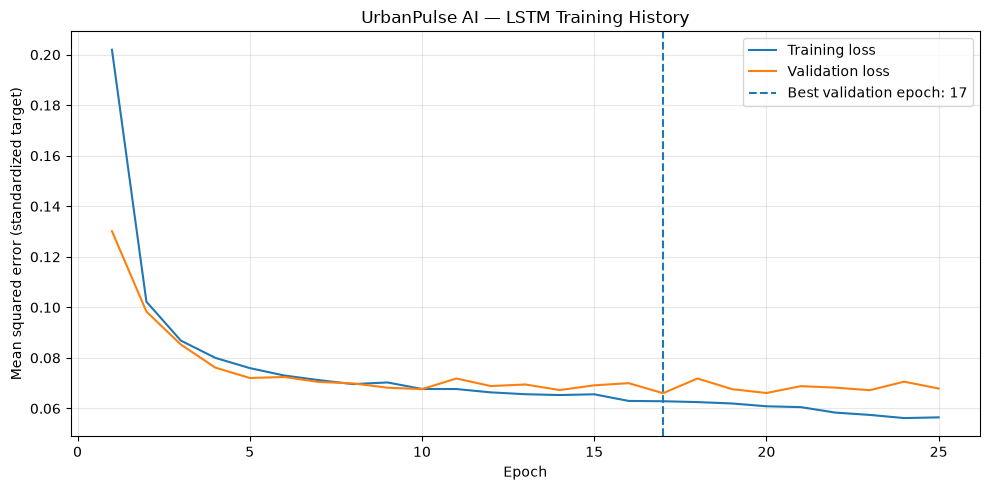

In [22]:
# 6.3 — Inspect training dynamics and possible overfitting

import matplotlib.pyplot as plt

epochs = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(10, 5))
plt.plot(
    epochs,
    history.history["loss"],
    label="Training loss"
)
plt.plot(
    epochs,
    history.history["val_loss"],
    label="Validation loss"
)
plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best validation epoch: {best_epoch}"
)

plt.title("UrbanPulse AI — LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error (standardized target)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7 — Final Evaluation on the Held-Out Test Set

### Objective

Evaluate the selected LSTM model on the chronological test partition, which was not used for training, early stopping, or model selection.

### Evaluation Protocol

The LSTM and persistence baseline will be evaluated on identical test observations for which the next-hour PM2.5 target and current-hour PM2.5 measurement are both available.

The evaluation reports mean absolute error (MAE), root mean squared error (RMSE), and the coefficient of determination (\(R^2\)). Test results provide an estimate of performance on this held-out period; they do not guarantee performance at other stations or in other cities.

In [23]:
# 7.1 — Evaluate the frozen LSTM on the held-out test partition

# Generate predictions without updating model weights.
test_predictions_scaled = lstm_model.predict(
    X_test_seq,
    batch_size=256,
    verbose=1
)

# Convert standardized predictions back to PM2.5 units.
test_predictions = target_scaler.inverse_transform(
    test_predictions_scaled
).ravel()

y_test_original = np.asarray(y_test_raw, dtype=np.float64)

# Fair comparison: both models must have the same valid observations.
common_test_mask = (
    np.isfinite(test_current_pm25)
    & np.isfinite(y_test_original)
    & np.isfinite(test_predictions)
)

if common_test_mask.sum() == 0:
    raise ValueError("No common test observations for evaluation.")

y_test_eval = y_test_original[common_test_mask]
lstm_test_eval = test_predictions[common_test_mask]
persistence_test_eval = test_current_pm25[common_test_mask]

lstm_test_mae = mean_absolute_error(
    y_test_eval, lstm_test_eval
)
lstm_test_rmse = np.sqrt(
    mean_squared_error(y_test_eval, lstm_test_eval)
)
lstm_test_r2 = r2_score(
    y_test_eval, lstm_test_eval
)

persistence_test_mae = mean_absolute_error(
    y_test_eval, persistence_test_eval
)
persistence_test_rmse = np.sqrt(
    mean_squared_error(y_test_eval, persistence_test_eval)
)
persistence_test_r2 = r2_score(
    y_test_eval, persistence_test_eval
)

test_comparison = pd.DataFrame([
    {
        "Model": "Persistence",
        "MAE (µg/m³)": persistence_test_mae,
        "RMSE (µg/m³)": persistence_test_rmse,
        "R²": persistence_test_r2,
    },
    {
        "Model": "LSTM",
        "MAE (µg/m³)": lstm_test_mae,
        "RMSE (µg/m³)": lstm_test_rmse,
        "R²": lstm_test_r2,
    },
])

print("Held-out test evaluation")
print("-" * 55)
print("Common test observations:", int(common_test_mask.sum()))
display(test_comparison.round(4))

test_mae_improvement = (
    (persistence_test_mae - lstm_test_mae)
    / persistence_test_mae
) * 100

test_rmse_improvement = (
    (persistence_test_rmse - lstm_test_rmse)
    / persistence_test_rmse
) * 100

print(f"MAE improvement vs persistence:  {test_mae_improvement:+.2f}%")
print(f"RMSE improvement vs persistence: {test_rmse_improvement:+.2f}%")

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step
Held-out test evaluation
-------------------------------------------------------
Common test observations: 5139


,Model,MAE (µg/m³),RMSE (µg/m³),R²
0,Persistence,11.0272,20.9235,0.9500
1,LSTM,11.4519,20.2557,0.9532


MAE improvement vs persistence:  -3.85%
RMSE improvement vs persistence: +3.19%


LSTM test residual diagnostics
-------------------------------------------------------
Mean residual: -4.0429
Median residual: -2.0046
Residual standard deviation: 19.8481
Largest absolute error: 292.3405


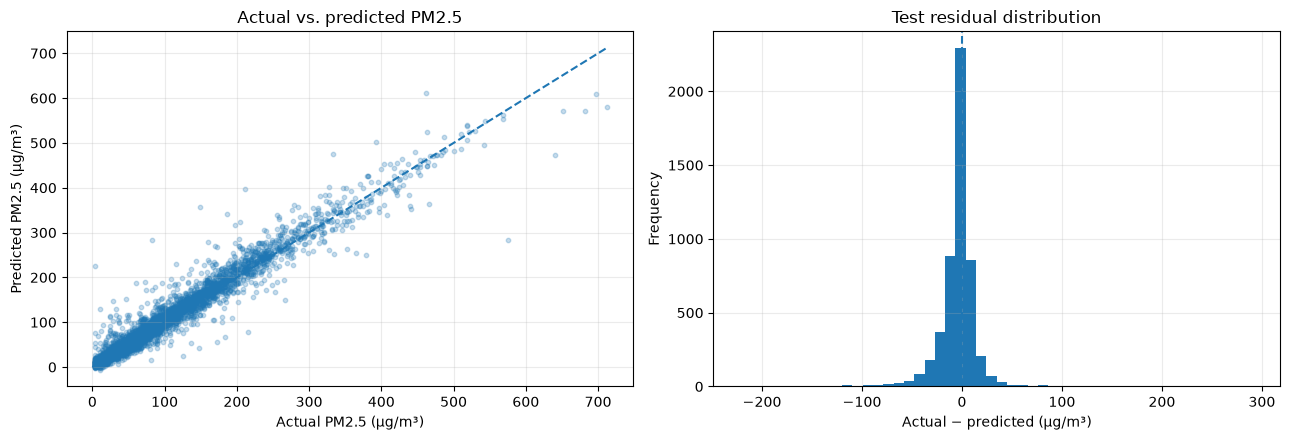

In [24]:
# 7.2 — Inspect held-out test residuals

test_residuals = y_test_eval - lstm_test_eval

print("LSTM test residual diagnostics")
print("-" * 55)
print("Mean residual:", round(float(np.mean(test_residuals)), 4))
print("Median residual:", round(float(np.median(test_residuals)), 4))
print("Residual standard deviation:",
      round(float(np.std(test_residuals)), 4))
print("Largest absolute error:",
      round(float(np.max(np.abs(test_residuals))), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(
    y_test_eval,
    lstm_test_eval,
    alpha=0.25,
    s=10
)
upper = max(float(np.max(y_test_eval)), float(np.max(lstm_test_eval)))
axes[0].plot([0, upper], [0, upper], linestyle="--")
axes[0].set_title("Actual vs. predicted PM2.5")
axes[0].set_xlabel("Actual PM2.5 (µg/m³)")
axes[0].set_ylabel("Predicted PM2.5 (µg/m³)")
axes[0].grid(True, alpha=0.25)

axes[1].hist(test_residuals, bins=50)
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Test residual distribution")
axes[1].set_xlabel("Actual − predicted (µg/m³)")
axes[1].set_ylabel("Frequency")
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

In [25]:
# 7.3 — Compare errors across actual PM2.5 concentration ranges

test_error_analysis = pd.DataFrame({
    "Actual_PM2.5": y_test_eval,
    "LSTM_Predicted": lstm_test_eval,
    "Persistence_Predicted": persistence_test_eval,
})

test_error_analysis["Pollution_Range"] = pd.cut(
    test_error_analysis["Actual_PM2.5"],
    bins=[-np.inf, 35, 75, 150, 250, np.inf],
    labels=[
        "0–35",
        ">35–75",
        ">75–150",
        ">150–250",
        ">250",
    ],
    right=True
)

test_error_analysis["LSTM_Absolute_Error"] = np.abs(
    test_error_analysis["Actual_PM2.5"]
    - test_error_analysis["LSTM_Predicted"]
)

test_error_analysis["Persistence_Absolute_Error"] = np.abs(
    test_error_analysis["Actual_PM2.5"]
    - test_error_analysis["Persistence_Predicted"]
)

pollution_range_results = (
    test_error_analysis
    .groupby("Pollution_Range", observed=False)
    .agg(
        Observations=("Actual_PM2.5", "count"),
        Mean_Actual_PM2_5=("Actual_PM2.5", "mean"),
        LSTM_MAE=("LSTM_Absolute_Error", "mean"),
        Persistence_MAE=("Persistence_Absolute_Error", "mean"),
    )
    .reset_index()
)

display(pollution_range_results.round(3))

,Pollution_Range,Observations,Mean_Actual_PM2_5,LSTM_MAE,Persistence_MAE
0,0–35,2063,15.829,5.494,5.609
1,>35–75,1000,54.779,10.303,9.817
2,>75–150,1067,108.245,14.207,13.405
3,>150–250,679,193.065,19.757,18.009
4,>250,330,343.694,26.179,26.515


Section 8 — Save the experiment artifacts

In [26]:
# 8.1 — Save the model, metrics, and prediction records

from pathlib import Path
import json

project_root = Path(r"C:\UrbanPulse-AI")
model_dir = project_root / "models"
report_dir = project_root / "reports"

model_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "urbanpulse_lstm_pm25.keras"
metrics_path = report_dir / "lstm_test_metrics.json"
predictions_path = report_dir / "lstm_test_predictions.csv"

# Save the selected model with its restored best validation weights.
lstm_model.save(model_path)

# Save test metrics.
metrics_payload = {
    "experiment": "UrbanPulse AI LSTM one-hour-ahead PM2.5",
    "station": "Aotizhongxin",
    "lookback_hours": LOOKBACK,
    "forecast_horizon_hours": 1,
    "input_features": feature_columns,
    "best_validation_epoch": best_epoch,
    "common_test_observations": int(common_test_mask.sum()),
    "persistence": {
        "mae": float(persistence_test_mae),
        "rmse": float(persistence_test_rmse),
        "r2": float(persistence_test_r2),
    },
    "lstm": {
        "mae": float(lstm_test_mae),
        "rmse": float(lstm_test_rmse),
        "r2": float(lstm_test_r2),
    },
    "improvement_percent": {
        "mae": float(test_mae_improvement),
        "rmse": float(test_rmse_improvement),
    },
}

with metrics_path.open("w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)

# Save timestamps and predictions for reproducible analysis.
prediction_records = pd.DataFrame({
    "target_timestamp": test_prediction_times[common_test_mask],
    "actual_PM2.5": y_test_eval,
    "LSTM_predicted_PM2.5": lstm_test_eval,
    "persistence_predicted_PM2.5": persistence_test_eval,
})

prediction_records.to_csv(predictions_path, index=False)

print("Saved experiment artifacts:")
print("Model:", model_path)
print("Metrics:", metrics_path)
print("Predictions:", predictions_path)

Saved experiment artifacts:
Model: C:\UrbanPulse-AI\models\urbanpulse_lstm_pm25.keras
Metrics: C:\UrbanPulse-AI\reports\lstm_test_metrics.json
Predictions: C:\UrbanPulse-AI\reports\lstm_test_predictions.csv


## Results and Discussion — LSTM-Based PM2.5 Forecasting

The LSTM model was developed to forecast PM2.5 concentration one hour ahead using 24-hour input sequences containing 11 pollutant and meteorological features. Training used chronological data partitions, with early stopping based on validation loss. The model achieved its lowest recorded validation loss at epoch 17.

On the held-out test partition, 5,139 observations were available for a common comparison between the LSTM and persistence baseline. The LSTM achieved a mean absolute error (MAE) of 11.4519 µg/m³, a root mean squared error (RMSE) of 20.2557 µg/m³, and an R² of 0.9532. The persistence baseline achieved an MAE of 11.0272 µg/m³, an RMSE of 20.9235 µg/m³, and an R² of 0.9500.

Relative to persistence, the LSTM reduced RMSE by approximately 3.19% and increased R² by 0.0032, but its MAE was approximately 3.85% higher. These results indicate that the LSTM reduced the overall squared-error penalty but did not improve the average absolute error. Consequently, the model cannot be described as uniformly superior to the baseline.

Performance also varied by pollution range. The LSTM achieved lower MAE in the 0–35 µg/m³ and above-250 µg/m³ groups, while persistence achieved lower MAE in the three intermediate groups. The highest concentration group contained 330 observations, and the difference between the models in that group was modest. The largest absolute LSTM error was 292.3405 µg/m³.

Residual diagnostics showed a mean residual of −4.0429 µg/m³ and a median residual of −2.0046 µg/m³, using the definition actual minus predicted. These negative values indicate a tendency toward overprediction on average. Therefore, the residual analysis does not support describing the model as unbiased.

Overall, the experiment demonstrates that an LSTM can provide competitive one-hour-ahead PM2.5 forecasts, but its benefits depend on the evaluation metric and pollution range. Further work should investigate systematic residual bias, error patterns across pollution levels, and whether additional temporal features or alternative architectures can improve upon persistence. Conclusions are limited to the selected station, dataset, forecasting horizon, and chronological test period.

## Milestone 6 — Explainable AI (XAI)

### 6.1 — Permutation Feature Importance for the LSTM

**Objective**

Estimate how much the LSTM's validation RMSE changes when the temporal history of one input feature is shuffled across validation samples.

**Methodology**

- Use the trained LSTM and validation observations only.
- Evaluate the same observations for every feature.
- Shuffle each feature's complete 24-hour trajectory across samples.
- Repeat each permutation three times and average the resulting RMSE increases.
- Rank features by their average increase in RMSE.

A larger increase suggests greater model reliance on that feature under this permutation procedure. This is a model-dependence analysis, not proof of causality. Correlated pollutants and weather variables can share predictive information, and shuffling may create combinations that are uncommon in real observations.

In [27]:
# 6.1 — Prepare a consistent validation reference for XAI

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import mean_squared_error

# Reuse the model already trained in this notebook.
# If needed, load the saved model.
if "model" in globals():
    xai_model = model
elif "lstm_model" in globals():
    xai_model = lstm_model
else:
    from tensorflow.keras.models import load_model
    xai_model = load_model(
        r"C:\UrbanPulse-AI\models\urbanpulse_lstm_pm25.keras"
    )

# Use the same validation observations available to the persistence baseline.
xai_mask = np.asarray(val_common_mask, dtype=bool)

X_xai = X_val_seq[xai_mask]
y_xai = y_val_raw[xai_mask].reshape(-1)

if len(X_xai) != len(y_xai) or len(y_xai) == 0:
    raise ValueError("Validation inputs and targets do not align.")

# Convert model predictions from standardized units back to µg/m³.
pred_scaled = xai_model.predict(X_xai, verbose=0)
pred_original = target_scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).reshape(-1)

baseline_rmse = float(
    np.sqrt(mean_squared_error(y_xai, pred_original))
)

print("XAI validation reference")
print("-" * 50)
print("Validation observations:", len(y_xai))
print("Sequence shape:", X_xai.shape)
print(f"Baseline LSTM RMSE: {baseline_rmse:.4f} µg/m³")
print("Features:", feature_columns)

XAI validation reference
--------------------------------------------------
Validation observations: 5107
Sequence shape: (5107, 24, 11)
Baseline LSTM RMSE: 19.8741 µg/m³
Features: ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']


In [30]:
# 6.2 — Estimate temporal permutation feature importance

from sklearn.metrics import mean_squared_error

N_REPEATS = 3
rng = np.random.default_rng(42)

importance_records = []

for feature_idx, feature_name in enumerate(feature_columns):
    repeat_rmses = []

    for repeat in range(N_REPEATS):
        X_permuted = X_xai.copy()

        # Shuffle whole 24-hour trajectories between validation samples.
        # Keep the order within each trajectory intact.
        permutation = rng.permutation(len(X_permuted))
        X_permuted[:, :, feature_idx] = (
            X_xai[permutation, :, feature_idx]
        )

        permuted_scaled = xai_model.predict(
            X_permuted,
            verbose=0
        )

        permuted_original = target_scaler.inverse_transform(
            permuted_scaled.reshape(-1, 1)
        ).reshape(-1)

        permuted_rmse = float(
            np.sqrt(
                mean_squared_error(y_xai, permuted_original)
            )
        )

        repeat_rmses.append(permuted_rmse)

    importance_records.append({
        "Feature": feature_name,
        "Baseline_RMSE": baseline_rmse,
        "Mean_Permuted_RMSE": float(np.mean(repeat_rmses)),
        "RMSE_Increase": float(
            np.mean(repeat_rmses) - baseline_rmse
        ),
        "Repeat_RMSE_Std": float(np.std(repeat_rmses, ddof=1)),
    })

importance_df = pd.DataFrame(importance_records).sort_values(
    "RMSE_Increase",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

,Feature,Baseline_RMSE,Mean_Permuted_RMSE,RMSE_Increase,Repeat_RMSE_Std
0,PM2.5,19.8741,97.3419,77.4678,0.6714
1,PM10,19.8741,26.0469,6.1728,0.1425
2,DEWP,19.8741,24.8738,4.9997,0.1123
3,TEMP,19.8741,23.9141,4.0400,0.0672
4,CO,19.8741,21.4432,1.5691,0.0785
5,NO2,19.8741,20.8833,1.0092,0.0172
6,WSPM,19.8741,20.7996,0.9255,0.1195
7,O3,19.8741,20.5376,0.6635,0.0419
8,RAIN,19.8741,20.1736,0.2995,0.1058
9,SO2,19.8741,20.1367,0.2626,0.0568


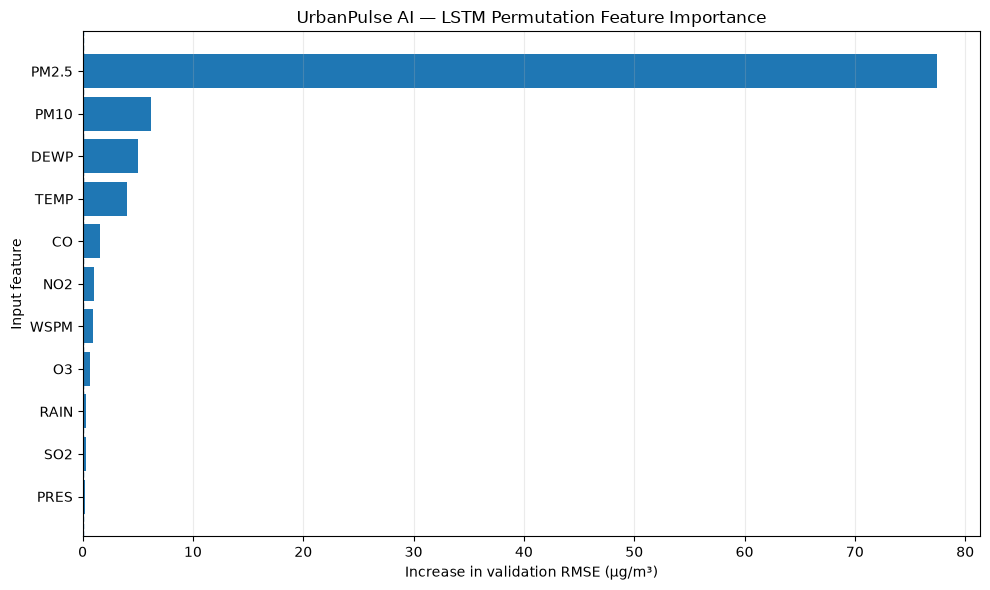

Saved: C:\UrbanPulse-AI\reports\lstm_permutation_feature_importance.csv


In [31]:
# 6.3 — Plot and save permutation feature importance

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["RMSE_Increase"][::-1]
)
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Increase in validation RMSE (µg/m³)")
plt.ylabel("Input feature")
plt.title("UrbanPulse AI — LSTM Permutation Feature Importance")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

xai_report_dir = Path(r"C:\UrbanPulse-AI\reports")
xai_report_dir.mkdir(parents=True, exist_ok=True)

importance_df.to_csv(
    xai_report_dir / "lstm_permutation_feature_importance.csv",
    index=False
)

print(
    "Saved:",
    xai_report_dir / "lstm_permutation_feature_importance.csv"
)